In [29]:
import pandas as pd
import numpy as np
import pandahouse
import seaborn as sns
import matplotlib.pyplot as plt
import orbit
import matplotlib.dates as mdates
from orbit.models import ETS, LGT, DLT, KTR
from orbit.diagnostics.plot import plot_predicted_data, plot_predicted_components
import logging
from orbit.diagnostics.backtest import BackTester

In [30]:
# Чем активнее наши пользователи – тем выше нагрузка на сервера. И в последнее время нам всё чаще приходят жалобы, 
# что приложение подвисает. Звучит как задача для девопсов и инженеров! От вас тоже попросили внести свой вклад 
# в задачу – спрогнозировать, как изменится активность пользователей в течение ближайшего месяца.

# 1. Выберите основную метрику, которую вы планируете прогнозировать. Обоснуйте, почему именно она. 
# Какое временное разрешение вы возьмёте? Будут ли какие-то дополнительные регрессоры, которые вы включите в модель?

# 2. Постройте модель и провалидируйте её. Хватает ли у нас данных для бэктестинга с текущей задачей? 
# Если нет, то определите, для какого горизонта прогнозирования у нас хватает данных.

# 3. Выберите ту модель, которая кажется вам наиболее удачной (обоснуйте выбор). Проинтерпретируйте её результаты. 
# Если есть какие-то важные ограничения по выводу – не забудьте их тоже указать.

# Бонус: опишите, насколько удобным для использования вам показался Orbit. Если есть опыт использования других прогнозных 
# инструментов (Prophet, Darts и т.д.) – сравните Orbit с ними по тем признакам, которые вам кажутся наиболее важными.
# Формат сдачи задания – merge request в GitLab с ноутбуком, где выполнены вычисления (формат .ipynb).

В качестве оснвной метрики я бы выбрала общее количество пользовательских действий за день (просмотры, лайки, сообщения), так как это лучше всего отражает интенсивность действий, которые и оказывают основную нагрузку на сервера. 

Временное разрешение - день, так как такая гранулярность позволит отслеживать недельную сезонность и предоставит достаточно детальную картину прогнозирования. 

В качестве регрессоров можно рассмотреть:
    1. Дни недели (для учета регулярных недельных активностей)
    2. Даты запланированных рекламных кампаний (если известно)
    3. Праздничные дни (если такие имеются и могут повлиять на поведение пользователей)

In [ ]:
# подключение к Clickhouse
connection = {
    'host': 'http://clickhouse.lab.karpov.courses:8123',
    'password': '',
    'user': 'student',
    'database': 'simulator_20261020'
}

In [32]:
# все доступные данные по активности и интенсивности использования сервисов пользователями 
q = """
WITH message AS (
    SELECT
        toDate(time) AS date,
        COUNT(user_id) AS total_actions_message,
        COUNT(DISTINCT user_id) AS dau_message
    FROM simulator_20261020.message_actions
    GROUP BY toDate(time)
),
feed AS (
    SELECT
        toDate(time) AS date,
        COUNT(user_id) AS total_actions_feed,
        COUNT(DISTINCT user_id) AS dau_feed
    FROM simulator_20261020.feed_actions
    GROUP BY toDate(time)
),
dau AS (
    SELECT
        date,
        COUNT(DISTINCT user_id) AS dau
    FROM (
        SELECT toDate(time) AS date, user_id
        FROM simulator_20261020.feed_actions
        UNION ALL
        SELECT toDate(time) AS date, user_id
        FROM simulator_20261020.message_actions
    ) t
    GROUP BY date
)
SELECT
    d.date AS date,
    ifNull(total_actions_feed, 0) + ifNull(total_actions_message, 0) AS total_actions,
    dau,
    total_actions_feed,
    dau_feed,
    total_actions_message,
    dau_message
FROM dau d
    LEFT JOIN message m ON d.date = m.date
    LEFT JOIN feed f ON d.date = f.date
WHERE d.date < today()
ORDER BY date
"""

daily_activity = pandahouse.read_clickhouse(q, connection=connection)

daily_activity.head()

,date,total_actions,dau,total_actions_feed,dau_feed,total_actions_message,dau_message
0,2026-09-05,12389,1045,9163,878,3226,234
1,2026-09-06,88481,2494,75586,2238,12895,623
2,2026-09-07,139381,3396,126484,3105,12897,522
3,2026-09-08,155693,4011,142796,3721,12897,498
4,2026-09-09,221856,4997,208958,4617,12898,691


In [33]:
# количество дней представленных в датасете
number_of_date = daily_activity['date'].count()

# проверка на то, есть ли пропущенные даты
full_range = pd.date_range(start=daily_activity['date'].min(), end=daily_activity['date'].max(), freq='D')
missing_count = len(full_range) - number_of_date

print(f'Кол-во дней в датасете: {number_of_date}')
print(f'Пропущено дней в датасете: {missing_count}')

Кол-во дней в датасете: 71
Пропущено дней в датасете: 0


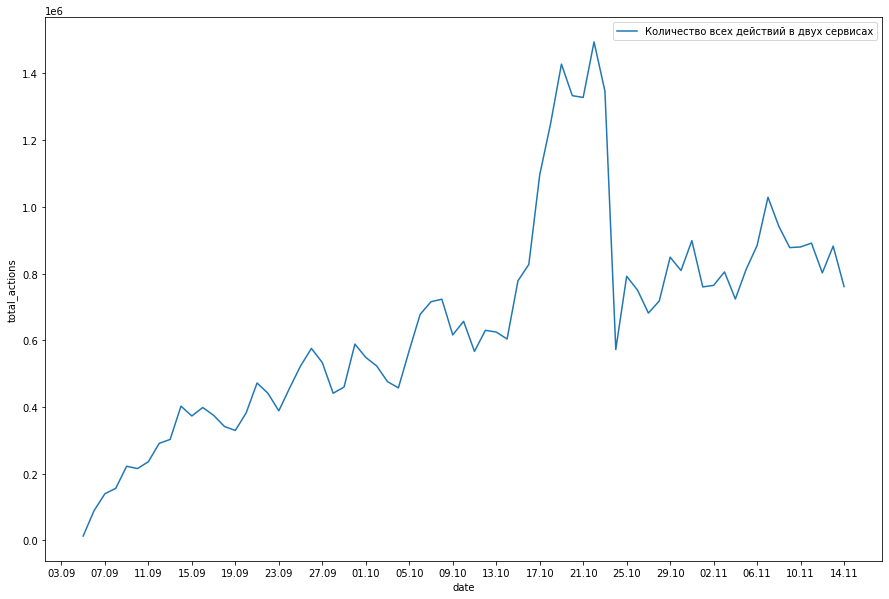

In [34]:
plt.figure(figsize=(15, 10))
ta = sns.lineplot(data=daily_activity, 
             x=daily_activity.date, 
             y=daily_activity.total_actions, 
             label='Количество всех действий в двух сервисах')

ta.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
ta.xaxis.set_major_locator(mdates.DayLocator(interval=4))

plt.show()

На протяжении рассматриваемого периода наблюдается общая тенденция к увелечению количества действий в сервисах.

В период с 16 по 22 октября заметен резкий всплеск активности, совпадающий по времени с проведением флешмоба в новостной ленте. После его завершения количество действий резко снизилось.

При этом даже после снижения активность остаётся выше уровня, наблюдавшегося в начале сентября. 

In [35]:
# все доступные данные по активности и интенсивности использования сервисов пользователями с агрегацией по дням недели
q = """
WITH message AS (
    SELECT
        toDate(time) AS date,
        COUNT(user_id) AS total_actions_message
    FROM simulator_20261020.message_actions
    GROUP BY toDate(time)
),
feed AS (
    SELECT
        toDate(time) AS date,
        COUNT(user_id) AS total_actions_feed
    FROM simulator_20261020.feed_actions
    GROUP BY toDate(time)
),
dau AS (
    SELECT
        date,
        COUNT(DISTINCT user_id) AS dau
    FROM (
        SELECT toDate(time) AS date, user_id
        FROM simulator_20261020.feed_actions
        UNION ALL
        SELECT toDate(time) AS date, user_id
        FROM simulator_20261020.message_actions
    ) t
    GROUP BY date
)
SELECT
    toDayOfWeek(date) AS day_of_week,
    ROUND(AVG(total_actions), 2) AS avg_actions,
    ROUND(AVG(dau), 2) AS avg_dau
FROM (
    SELECT
        d.date AS date,
        ifNull(total_actions_feed, 0) + ifNull(total_actions_message, 0) AS total_actions,
        dau
    FROM dau d
        LEFT JOIN message m ON d.date = m.date
        LEFT JOIN feed f ON d.date = f.date
    WHERE d.date < today()
)
GROUP BY day_of_week
"""

weekly_activity = pandahouse.read_clickhouse(q, connection=connection)

weekly_activity

,day_of_week,avg_actions,avg_dau
0,1,647348.00,14780.70
1,2,642973.40,14874.50
2,3,657596.20,15521.10
3,4,705435.30,15515.60
4,5,698770.10,14941.90
5,6,608695.09,13901.18
6,7,607170.70,14350.50


При анализе среднего количества пользовательских действий по дням недели наблюдается более высокая активность в будние дни по сравнению с выходными. Наибольшее количество действий приходится на четверг.

Полученные результаты могут указывать на наличие недельной сезонности, однако для подтверждения закономерности необходимо учитывать влияние аномальных периодов, в частности всплеска активности во время флешмоба.

In [36]:
# все доступные данные по активности и интенсивности использования сервисов пользователями с агрегацией по дням недели
# за исключением дней флешмоба
q = """
WITH message AS (
    SELECT
        toDate(time) AS date,
        COUNT(user_id) AS total_actions_message
    FROM simulator_20261020.message_actions
    GROUP BY toDate(time)
),
feed AS (
    SELECT
        toDate(time) AS date,
        COUNT(user_id) AS total_actions_feed
    FROM simulator_20261020.feed_actions
    GROUP BY toDate(time)
),
dau AS (
    SELECT
        date,
        COUNT(DISTINCT user_id) AS dau
    FROM (
        SELECT toDate(time) AS date, user_id
        FROM simulator_20261020.feed_actions
        UNION ALL
        SELECT toDate(time) AS date, user_id
        FROM simulator_20261020.message_actions
    ) t
    GROUP BY date
)
SELECT
    toDayOfWeek(date) AS day_of_week,
    ROUND(AVG(total_actions), 2) AS avg_actions,
    ROUND(AVG(dau), 2) AS avg_dau
FROM (
    SELECT
        d.date AS date,
        ifNull(total_actions_feed, 0) + ifNull(total_actions_message, 0) AS total_actions,
        dau
    FROM dau d
        LEFT JOIN message m ON d.date = m.date
        LEFT JOIN feed f ON d.date = f.date
    WHERE d.date <= '2026-10-15' OR (d.date > '2026-10-22' AND d.date < today())
)
GROUP BY day_of_week
"""

weekly_activity_without_flashmob = pandahouse.read_clickhouse(q, connection=connection)

weekly_activity_without_flashmob

,day_of_week,avg_actions,avg_dau
0,1,560609.78,14466.33
1,2,566250.78,14560.89
2,3,583082.11,15166.56
3,4,617734.44,15199.33
4,5,684492.89,14825.00
5,6,560010.50,13620.40
6,7,535820.67,13991.56


После исключения периода проведения флешмоба все еще наблюдается более высокая активность пользователей в будние 
дни по сравнению с выходными. Наибольшая активность наблюдается в пятницу.

Поскольку различия между буднями и выходными сохраняются даже после исключения аномального периода, можно предположить 
наличие недельной сезонности в данных.

In [37]:
weekly_activity['action_per_dau'] = weekly_activity['avg_actions'] / weekly_activity['avg_dau']

weekly_activity

,day_of_week,avg_actions,avg_dau,action_per_dau
0,1,647348.00,14780.70,43.796843
1,2,642973.40,14874.50,43.226556
2,3,657596.20,15521.10,42.367886
3,4,705435.30,15515.60,45.466195
4,5,698770.10,14941.90,46.765813
5,6,608695.09,13901.18,43.787296
6,7,607170.70,14350.50,42.310073


In [38]:
weekly_activity_without_flashmob['action_per_dau'] = weekly_activity_without_flashmob['avg_actions'] / weekly_activity_without_flashmob['avg_dau']

weekly_activity_without_flashmob

,day_of_week,avg_actions,avg_dau,action_per_dau
0,1,560609.78,14466.33,38.752730
1,2,566250.78,14560.89,38.888473
2,3,583082.11,15166.56,38.445245
3,4,617734.44,15199.33,40.642215
4,5,684492.89,14825.00,46.171527
5,6,560010.50,13620.40,41.115569
6,7,535820.67,13991.56,38.295992


Дополнительно была проанализирована интенсивность использования сервисов — среднее количество действий на одного 
активного пользователя (Actions per DAU). Наибольшая интенсивность наблюдается в пятницу.

После исключения периода флешмоба интенсивность использования в будние дни все так же выше, чем в выходные.
Это позволяет предположить, что более высокая активность в будние дни связана как с большим количеством активных 
пользователей, так и с несколько большей интенсивностью использования сервисов.

In [81]:
# блокировка вывода сообщений от модуля шрифтов
logging.getLogger('matplotlib.font_manager').disabled = True

# Отключаем INFO-сообщения от Orbit и Pyro
logging.getLogger('orbit').setLevel(logging.WARNING)
logging.getLogger('pyro').setLevel(logging.WARNING)

In [90]:
# определяем тренировочные и тестовые данные (на 7 дней)
horizon = 7

train = daily_activity.iloc[:-horizon]
test = daily_activity.iloc[-horizon:]

print('Train:', len(train))
print('Test:', len(test))
print('Train dates:', train['date'].min(), '-', train['date'].max())
print('Test dates:', test['date'].min(), '-', test['date'].max())

train

Train: 64
Test: 7
Train dates: 2026-09-05 00:00:00 - 2026-11-07 00:00:00
Test dates: 2026-11-08 00:00:00 - 2026-11-14 00:00:00


,date,total_actions,dau,total_actions_feed,dau_feed,total_actions_message,dau_message
0,2026-09-05,12389,1045,9163,878,3226,234
1,2026-09-06,88481,2494,75586,2238,12895,623
2,2026-09-07,139381,3396,126484,3105,12897,522
3,2026-09-08,155693,4011,142796,3721,12897,498
4,2026-09-09,221856,4997,208958,4617,12898,691
...,...,...,...,...,...,...,...
59,2026-11-03,804894,21522,791993,20061,12901,1662
60,2026-11-04,723540,22647,710641,20400,12899,2540
61,2026-11-05,813066,21805,800166,20198,12900,1823
62,2026-11-06,883874,21389,870974,19878,12900,1736


## ETS

In [82]:
ets = ETS(response_col="total_actions", #название колонки с метрикой
          date_col="date", #название колонки с датами-временем
          seasonality=7, #длина периода сезонности 
          estimator="stan-map", #алгоритм оценки
          n_bootstrap_draws=1000,
          num_warmup=2000, #время "разогрева"
          num_sample=1000) #количество сэмплов бутстрапа для доверительного интервала

In [83]:
# обучаем модель
ets.fit(train) #указываем данные, на которых строится модель

In [43]:
# датафрейм, для которого будем делать прогноз
future_df_ets = ets.make_future_df(periods=horizon)

In [44]:
# прогнозирование
predicted_df_ets = ets.predict(df=future_df_ets)

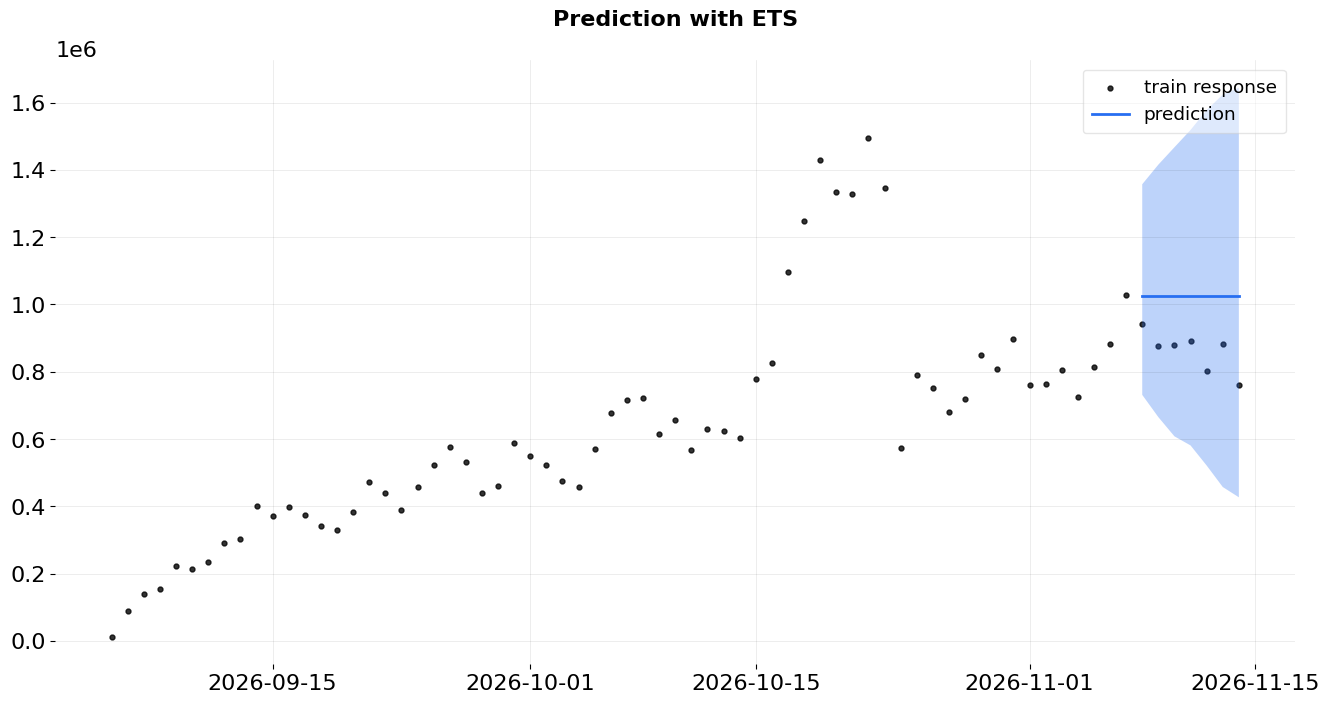

<Axes: title={'center': 'Prediction with ETS'}>

In [45]:
# визуализация прогноза
plot_predicted_data(daily_activity, #изначальные данные
                    predicted_df_ets, #датафрейм с предсказаниями
                    'date', #колонка со временем
                    'total_actions', #колонка со значениями временного ряда
                    title='Prediction with ETS') #заголовок рисунка

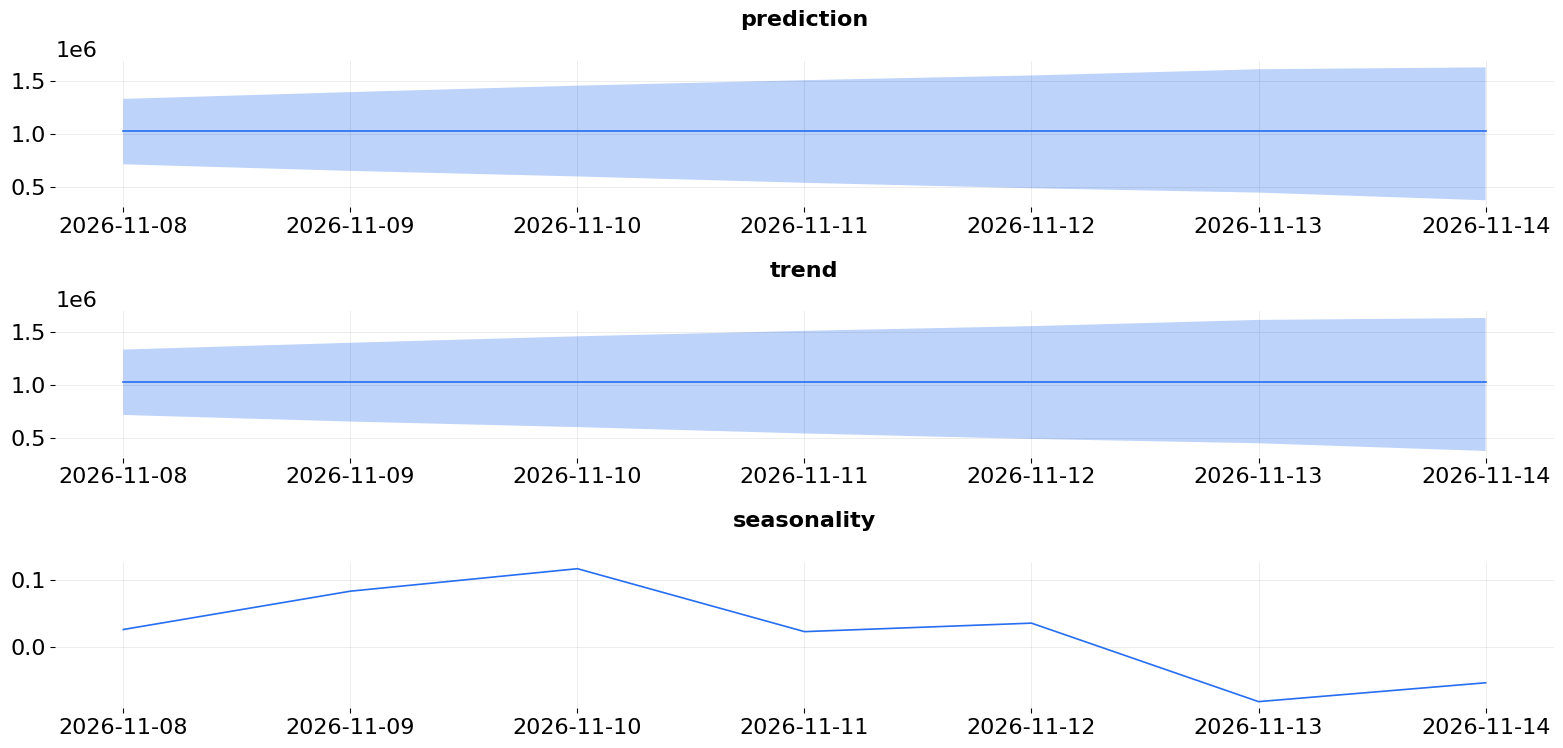

array([<Axes: title={'center': 'prediction'}>,
       <Axes: title={'center': 'trend'}>,
       <Axes: title={'center': 'seasonality'}>], dtype=object)

In [46]:
predicted_df_ets = ets.predict(df=future_df_ets, decompose=True)

plot_predicted_components(
    predicted_df_ets,
    'date',
    plot_components=['prediction', 'trend', 'seasonality']
)

## LGT

In [84]:
lgt = LGT(response_col="total_actions", #название колонки с метрикой
          date_col="date", #название колонки с датами-временем
          seasonality=7, #длина периода сезонности 
          estimator="stan-map", #алгоритм оценки
          n_bootstrap_draws=1000,
          num_warmup=2000, #время "разогрева"
          num_sample=1000) #количество сэмплов бутстрапа для доверительного интервала

In [85]:
# обучаем модель
lgt.fit(train) #указываем данные, на которых строится модель

In [52]:
# датафрейм, для которого будем делать прогноз
future_df_lgt = lgt.make_future_df(periods=horizon)

In [53]:
# прогнозирование
predicted_df_lgt = lgt.predict(df=future_df_lgt)

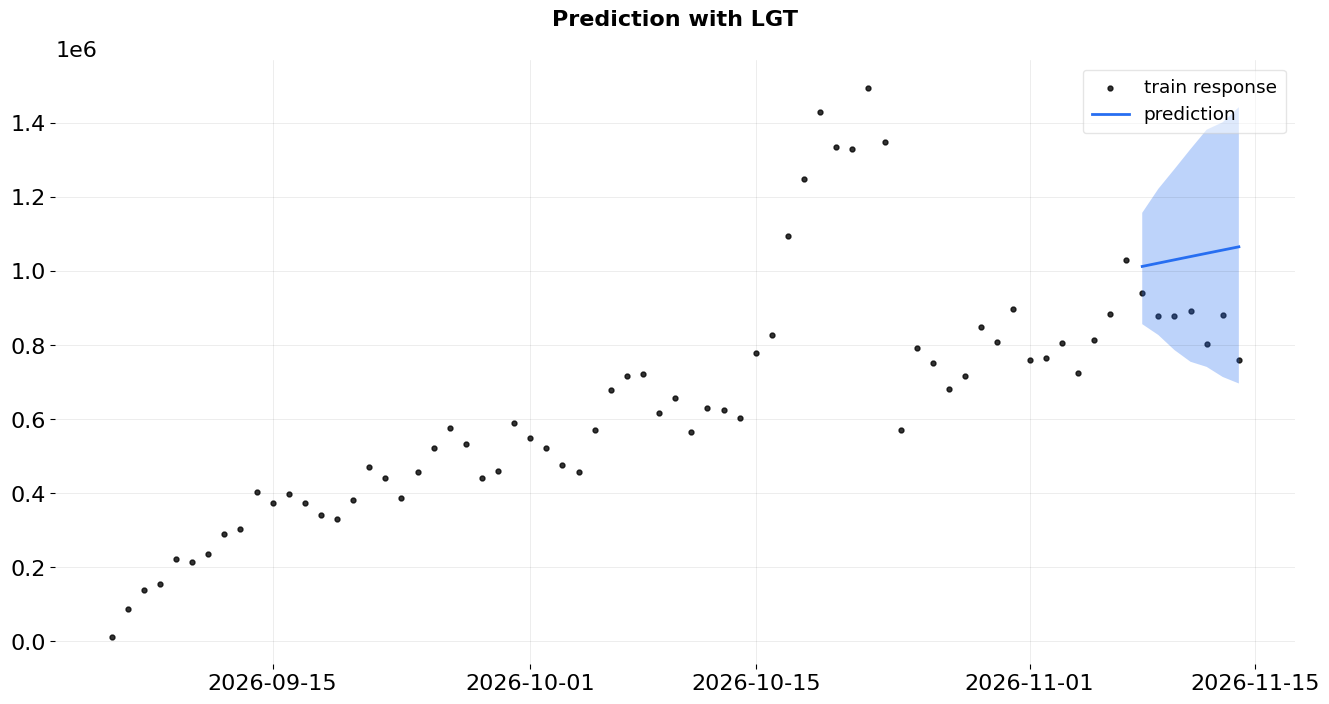

<Axes: title={'center': 'Prediction with LGT'}>

In [54]:
# визуализация прогноза
plot_predicted_data(daily_activity, #изначальные данные
                    predicted_df_lgt, #датафрейм с предсказаниями
                    'date', #колонка со временем
                    'total_actions', #колонка со значениями временного ряда
                    title='Prediction with LGT') #заголовок рисунка

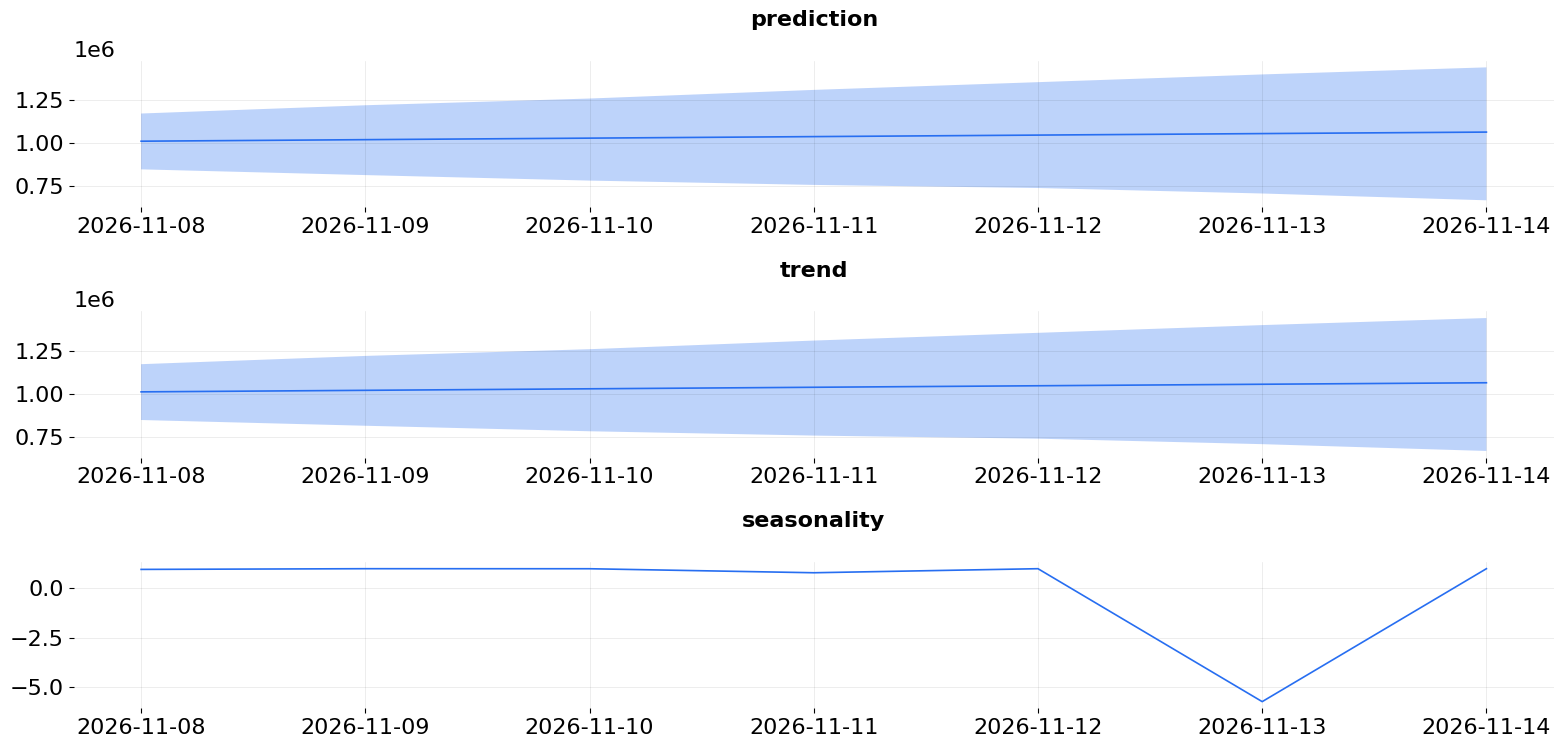

array([<Axes: title={'center': 'prediction'}>,
       <Axes: title={'center': 'trend'}>,
       <Axes: title={'center': 'seasonality'}>], dtype=object)

In [56]:
predicted_df_lgt = lgt.predict(df=future_df_lgt, decompose=True)

plot_predicted_components(
    predicted_df_lgt,
    'date',
    plot_components=['prediction', 'trend', 'seasonality']
)

## KTR

In [57]:
ktr = KTR(response_col="total_actions", #название колонки с метрикой
          date_col="date", #название колонки с датами-временем
          seasonality=7, #длина периода сезонности 
          estimator="pyro-svi", #алгоритм оценки
          n_bootstrap_draws=1000,
          num_steps=1000)

In [86]:
# обучаем модель
ktr.fit(train) #указываем данные, на которых строится модель

In [59]:
# датафрейм, для которого будем делать прогноз
future_df_ktr = ktr.make_future_df(periods=horizon)

In [60]:
# прогнозирование
predicted_df_ktr = ktr.predict(df=future_df_ktr)

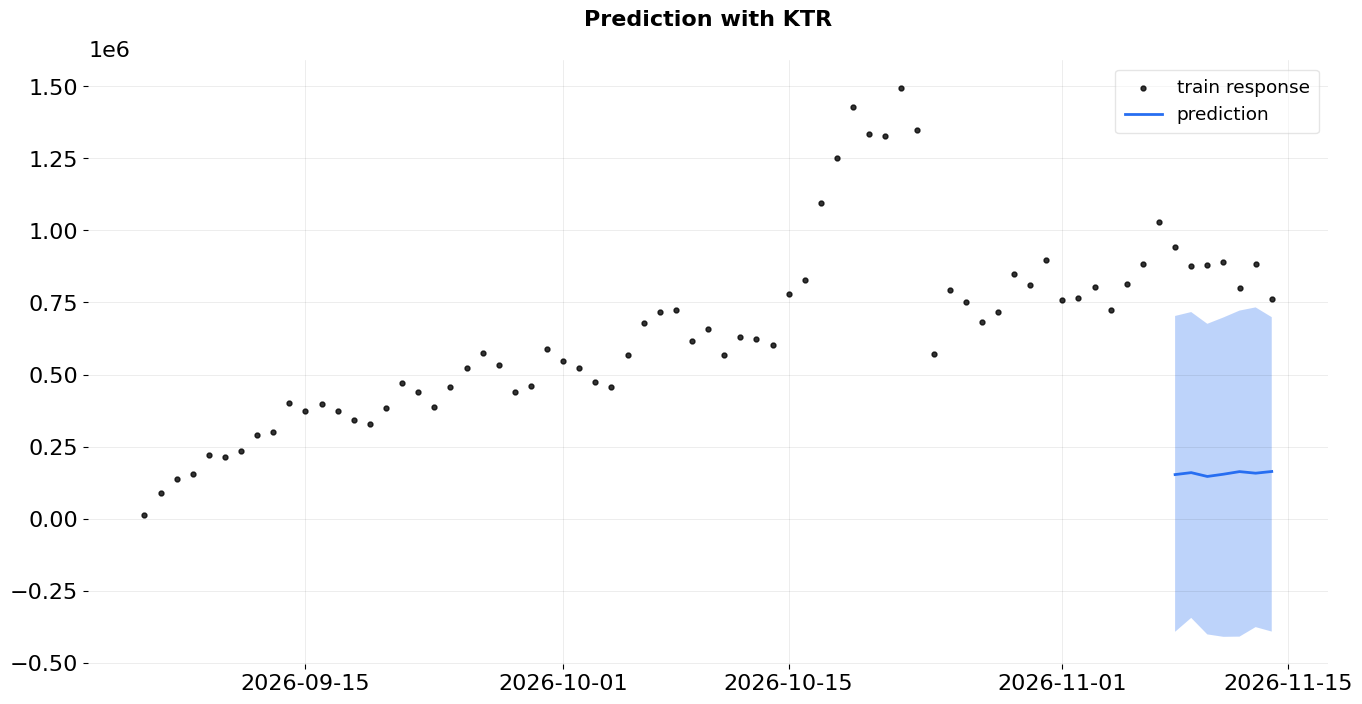

<Axes: title={'center': 'Prediction with KTR'}>

In [61]:
# визуализация прогноза
plot_predicted_data(daily_activity, #изначальные данные
                    predicted_df_ktr, #датафрейм с предсказаниями
                    'date', #колонка со временем
                    'total_actions', #колонка со значениями временного ряда
                    title='Prediction with KTR') #заголовок рисунка

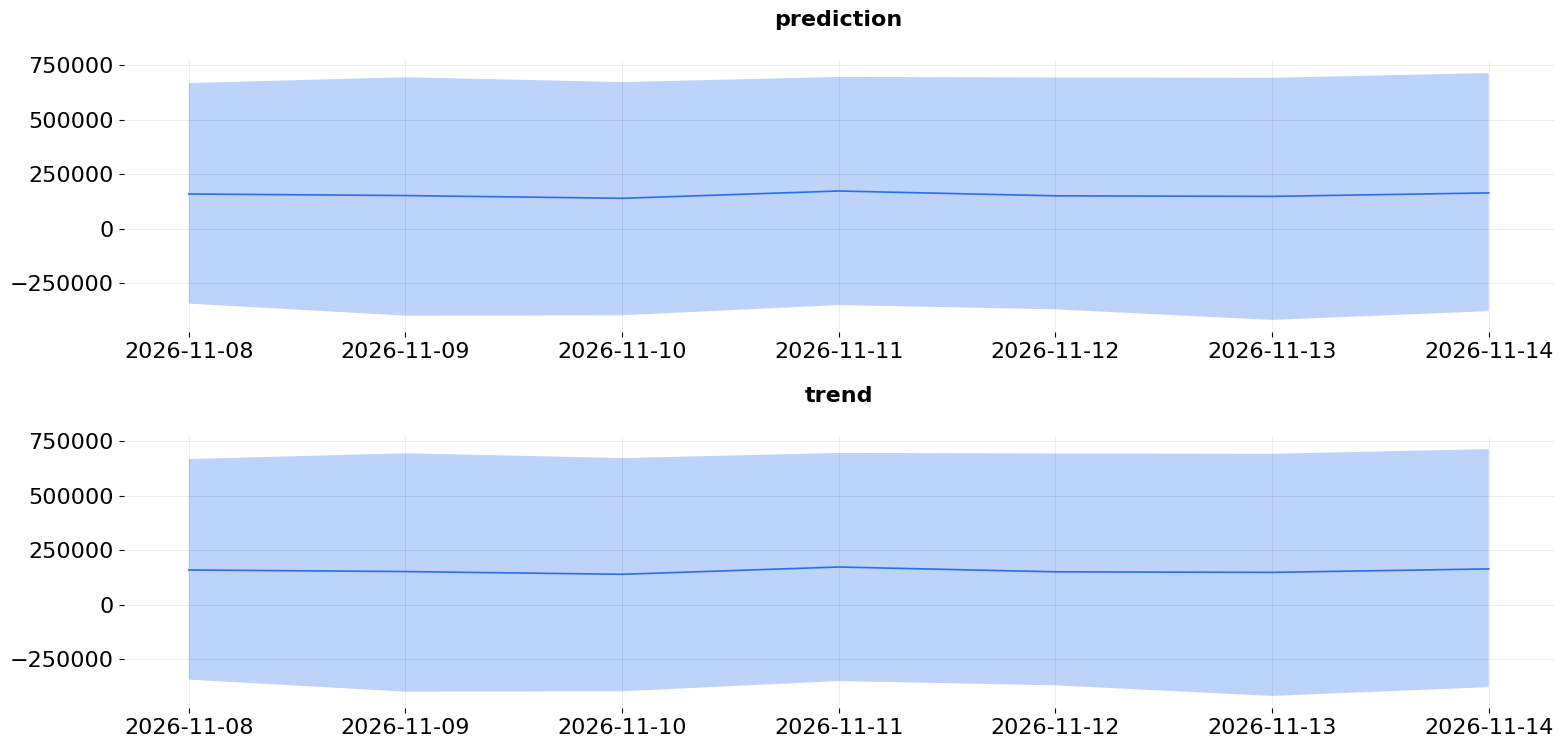

array([<Axes: title={'center': 'prediction'}>,
       <Axes: title={'center': 'trend'}>], dtype=object)

In [62]:
predicted_df_ktr = ktr.predict(df=future_df_ktr, decompose=True)

plot_predicted_components(
    predicted_df_ktr,
    'date',
    plot_components=['prediction', 'trend', 'seasonality']
)

## DLT

In [63]:
# задаем параметры модели 
dlt = DLT(response_col="total_actions", #название колонки с метрикой
          date_col="date", #название колонки с датами-временем
          seasonality=7, #длина периода сезонности 
          estimator="stan-map", #алгоритм оценки
          n_bootstrap_draws=1000,
          num_warmup=2000, #время "разогрева"
          num_sample=1000) #количество сэмплов бутстрапа для доверительного интервала

2026-11-15 18:11:13 - orbit - INFO - Optimizing (PyStan) with algorithm: LBFGS.


In [64]:
# обучаем модель
dlt.fit(train) #указываем данные, на которых строится модель

2026-11-15 18:11:13 - orbit - INFO - First time in running stan model:dlt. Expect 3 - 5 minutes for compilation.


In [65]:
# датафрейм, для которого будем делать прогноз
future_df_dtl = dlt.make_future_df(periods=horizon)

In [66]:
# прогнозирование
predicted_df_dtl = dlt.predict(df=future_df_dtl)

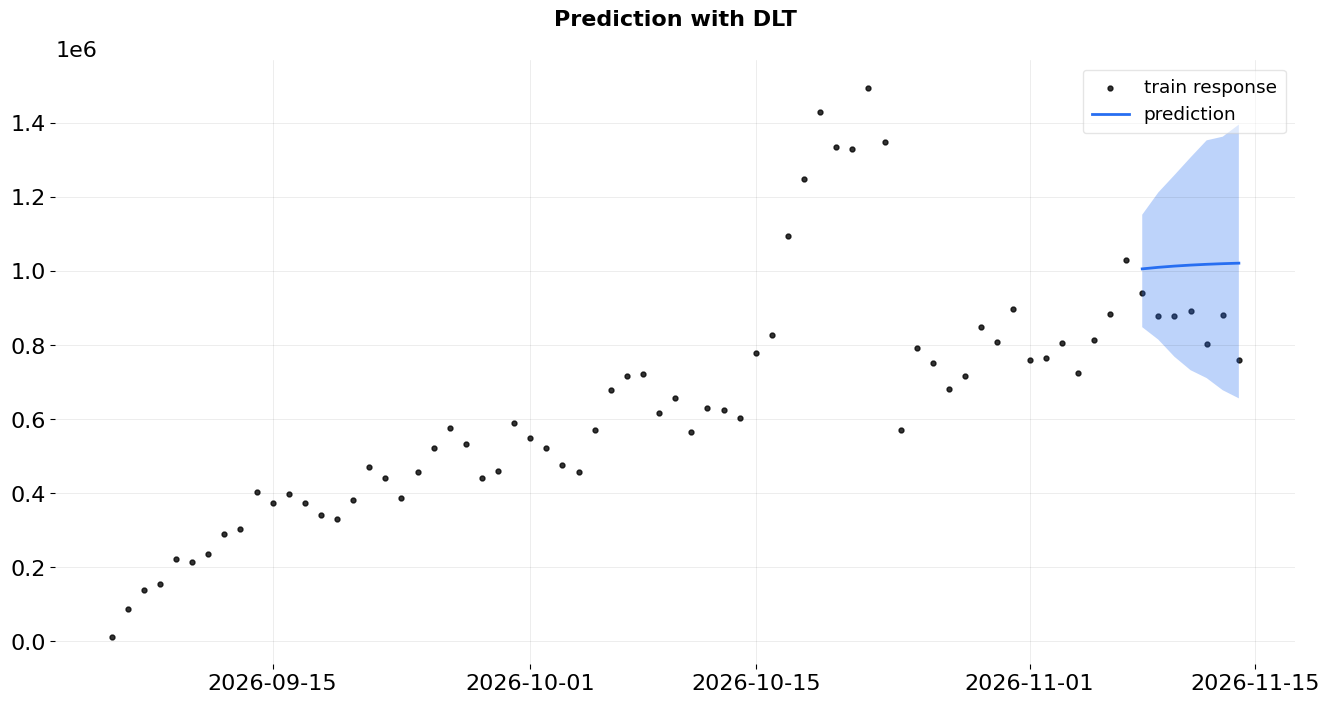

<Axes: title={'center': 'Prediction with DLT'}>

In [67]:
# визуализация прогноза
plot_predicted_data(daily_activity, #изначальные данные
                    predicted_df_dtl, #датафрейм с предсказаниями
                    'date', #колонка со временем
                    'total_actions', #колонка со значениями временного ряда
                    title='Prediction with DLT') #заголовок рисунка

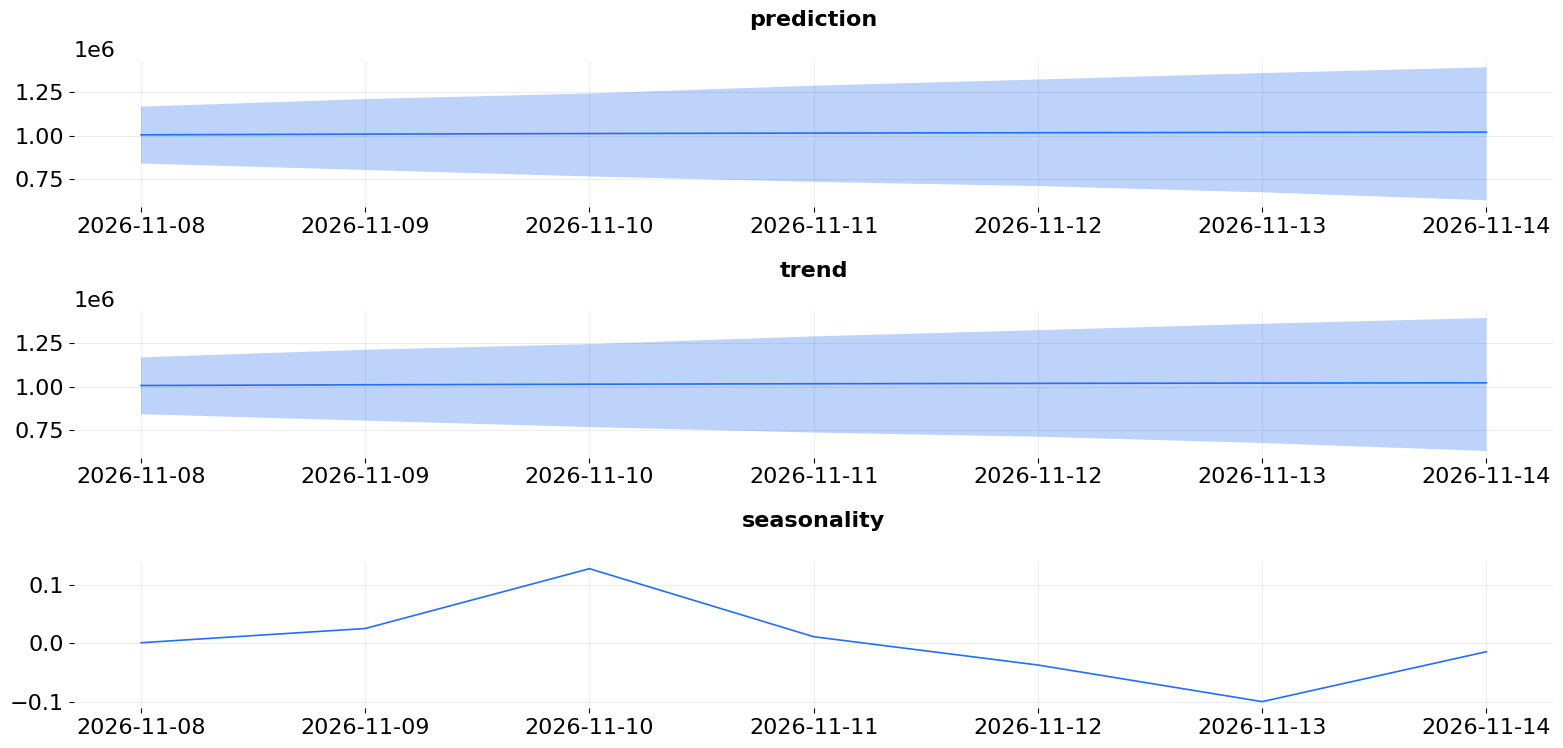

array([<Axes: title={'center': 'prediction'}>,
       <Axes: title={'center': 'trend'}>,
       <Axes: title={'center': 'seasonality'}>], dtype=object)

In [70]:
predicted_df_dtl = dlt.predict(df=future_df_dtl, decompose=True)

plot_predicted_components(
    predicted_df_dtl,
    'date',
    plot_components=['prediction', 'trend', 'seasonality']
)

## Сравнение моделей

In [71]:
def run_backtest(model, data, horizon=7):
    bt = BackTester(
        model,
        data,
        min_train_len=35,
        incremental_len=7,
        forecast_len=horizon,
        window_type='expanding'
    )

    bt.fit_predict()

    return bt

In [87]:
bt_ets = run_backtest(ets, daily_activity)
bt_lgt = run_backtest(lgt, daily_activity)
bt_dlt = run_backtest(dlt, daily_activity)
bt_ktr = run_backtest(ktr, daily_activity)

results = []

for name, bt in [
    ('ETS', bt_ets),
    ('LGT', bt_lgt),
    ('DLT', bt_dlt),
    ('KTR', bt_ktr)
]:
    score = bt.score()

    score['model'] = name

    results.append(score)

comparison = pd.concat(results, ignore_index=True)

comparison.pivot(
    index='model',
    columns='metric_name',
    values='metric_values'
).round(3)

metric_name,mae,mape,mse,rmsse,smape,wmape
model,,,,,,
DLT,254392.508,0.296,1.284286e+11,2.086,0.249,0.286
ETS,256915.250,0.289,1.350610e+11,2.139,0.254,0.289
KTR,737158.312,0.819,6.032431e+11,4.522,1.391,0.830
LGT,257062.888,0.296,1.253174e+11,2.061,0.254,0.289


По результатам бэктестинга на горизонте 7 дней наилучшее качество показали DLT, ETS и LGT. Их метрики оказались близкими, при этом DLT продемонстрировала минимальные MAE, SMAPE и WMAPE, ETS — минимальный MAPE, а LGT — минимальные MSE и RMSSE. Для дальнейшего сравнения выбраны DLT и ETS.

## DTL с регрессором

In [74]:
# модель с регрессором
dlt_reg = DLT(
    response_col='total_actions',
    date_col='date',
    seasonality=7,
    estimator='stan-map',
    n_bootstrap_draws=1000,
    regressor_col=['dau'],
    num_warmup=2000, #время "разогрева"
    num_sample=1000
)

2026-11-15 18:36:55 - orbit - INFO - Optimizing (PyStan) with algorithm: LBFGS.


In [75]:
# обучаем модель
dlt_reg.fit(train) #указываем данные, на которых строится модель

In [76]:
# датафрейм, для которого будем делать прогноз
future_df_reg = dlt_reg.make_future_df(periods=horizon)

# добавляем регрессор
future_df_reg = future_df_reg.merge(daily_activity[['date', 'dau']], how='left', on='date')

In [77]:
# прогнозирование
predicted_df_reg= dlt_reg.predict(df=future_df_reg)

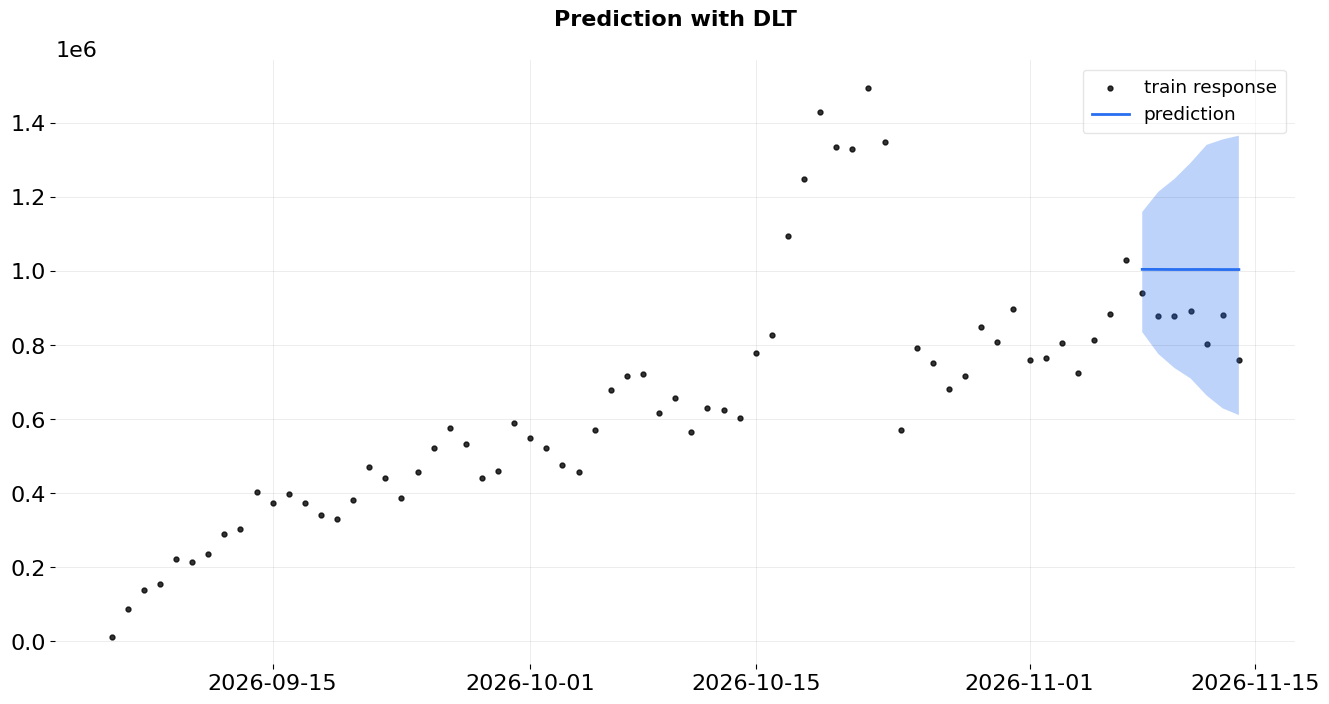

<Axes: title={'center': 'Prediction with DLT'}>

In [78]:
# визуализация прогноза
plot_predicted_data(daily_activity, #изначальные данные
                    predicted_df_reg, #датафрейм с предсказаниями
                    'date', #колонка со временем
                    'total_actions', #колонка со значениями временного ряда
                    title='Prediction with DLT') #заголовок рисунка

In [80]:
results = []

bt_dlt_reg = run_backtest(dlt_reg, daily_activity)

for name, bt in [
    ('DLT', bt_dlt),
    ('DLT + DAU', bt_dlt_reg),
    ('ETS', bt_ets)
]:
    score = bt.score()
    score['model'] = name
    results.append(score)

comparison = pd.concat(results, ignore_index=True)

comparison.pivot(
    index='model',
    columns='metric_name',
    values='metric_values'
).round(3)

metric_name,mae,mape,mse,rmsse,smape,wmape
model,,,,,,
DLT,254400.430,0.296,1.284299e+11,2.086,0.249,0.286
DLT + DAU,270865.118,0.307,1.442552e+11,2.211,0.267,0.305
ETS,256915.231,0.289,1.350610e+11,2.139,0.254,0.289


Добавление DAU в качестве регрессора не улучшило качество прогнозирования DLT. По всем рассмотренным метрикам модель с регрессором показала более высокую ошибку по сравнению с базовой DLT. Несмотря на достаточно сильную корреляцию между DAU и количеством действий, включение этой переменной не привело к повышению точности прогноза. Поэтому на данном этапе использование DAU в качестве регрессора не оправдано.

## DLT и ETS на горизонте 14 дней

In [144]:
# определяем тренировочные и тестовые данные (на 14 дней)
horizon_14 = 14

train_14 = daily_activity.iloc[:-horizon_14]
test_14 = daily_activity.iloc[-horizon_14:]

print('Train:', len(train_14))
print('Test:', len(test_14))
print('Train dates:', train_14['date'].min(), '-', train_14['date'].max())
print('Test dates:', test_14['date'].min(), '-', test_14['date'].max())

train_14.head()

Train: 57
Test: 14
Train dates: 2026-09-05 00:00:00 - 2026-10-31 00:00:00
Test dates: 2026-11-01 00:00:00 - 2026-11-14 00:00:00


,date,total_actions,dau,total_actions_feed,dau_feed,total_actions_message,dau_message
0,2026-09-05,12389,1045,9163,878,3226,234
1,2026-09-06,88481,2494,75586,2238,12895,623
2,2026-09-07,139381,3396,126484,3105,12897,522
3,2026-09-08,155693,4011,142796,3721,12897,498
4,2026-09-09,221856,4997,208958,4617,12898,691


In [94]:
dlt_14 = DLT(response_col="total_actions", #название колонки с метрикой
          date_col="date", #название колонки с датами-временем
          seasonality=7, #длина периода сезонности 
          estimator="stan-map", #алгоритм оценки
          n_bootstrap_draws=1000,
          num_warmup=2000, #время "разогрева"
          num_sample=1000) #количество сэмплов бутстрапа для доверительного интервала

In [95]:
# обучаем модель
dlt_14.fit(train_14)

In [117]:
# датафрейм, для которого будем делать прогноз
future_df_dtl_14 = dlt_14.make_future_df(periods=horizon_14)

In [97]:
# прогнозирование
predicted_df_dtl_14 = dlt_14.predict(df=future_df_dtl_14)

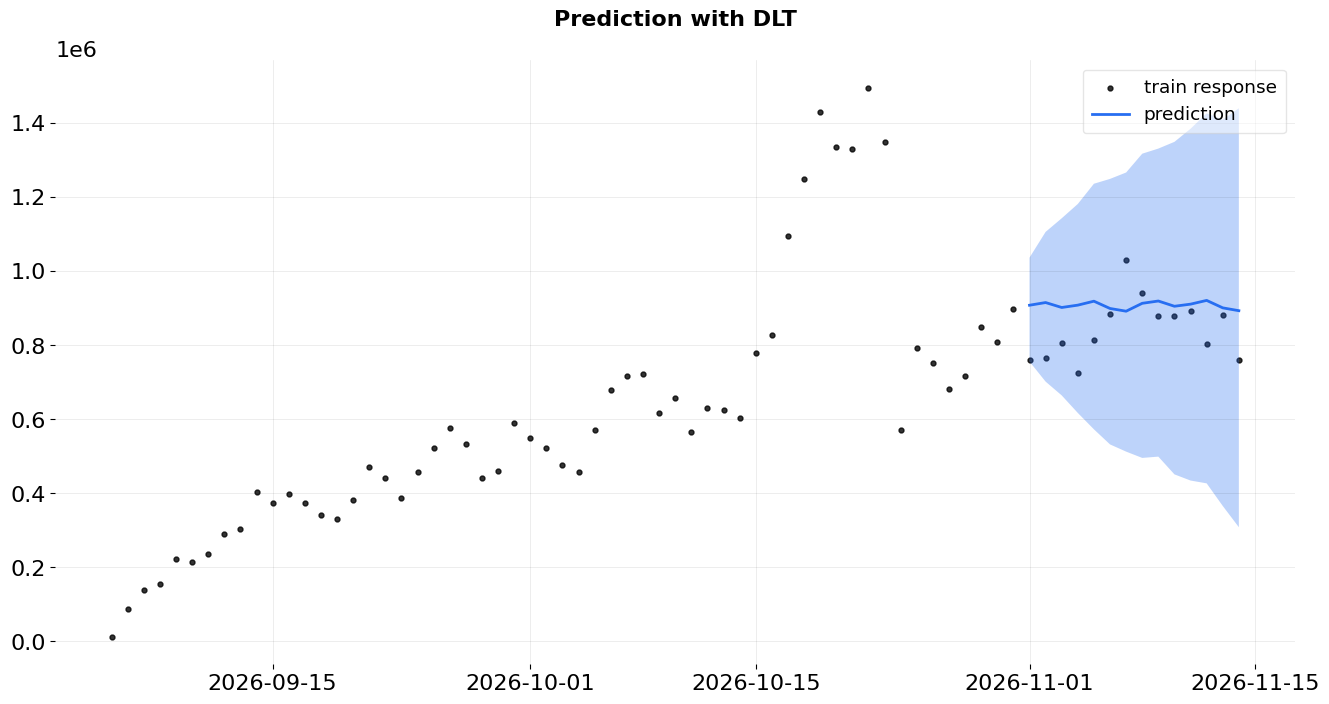

<Axes: title={'center': 'Prediction with DLT'}>

In [98]:
# визуализация прогноза
plot_predicted_data(daily_activity, #изначальные данные
                    predicted_df_dtl_14, #датафрейм с предсказаниями
                    'date', #колонка со временем
                    'total_actions', #колонка со значениями временного ряда
                    title='Prediction with DLT') #заголовок рисунка

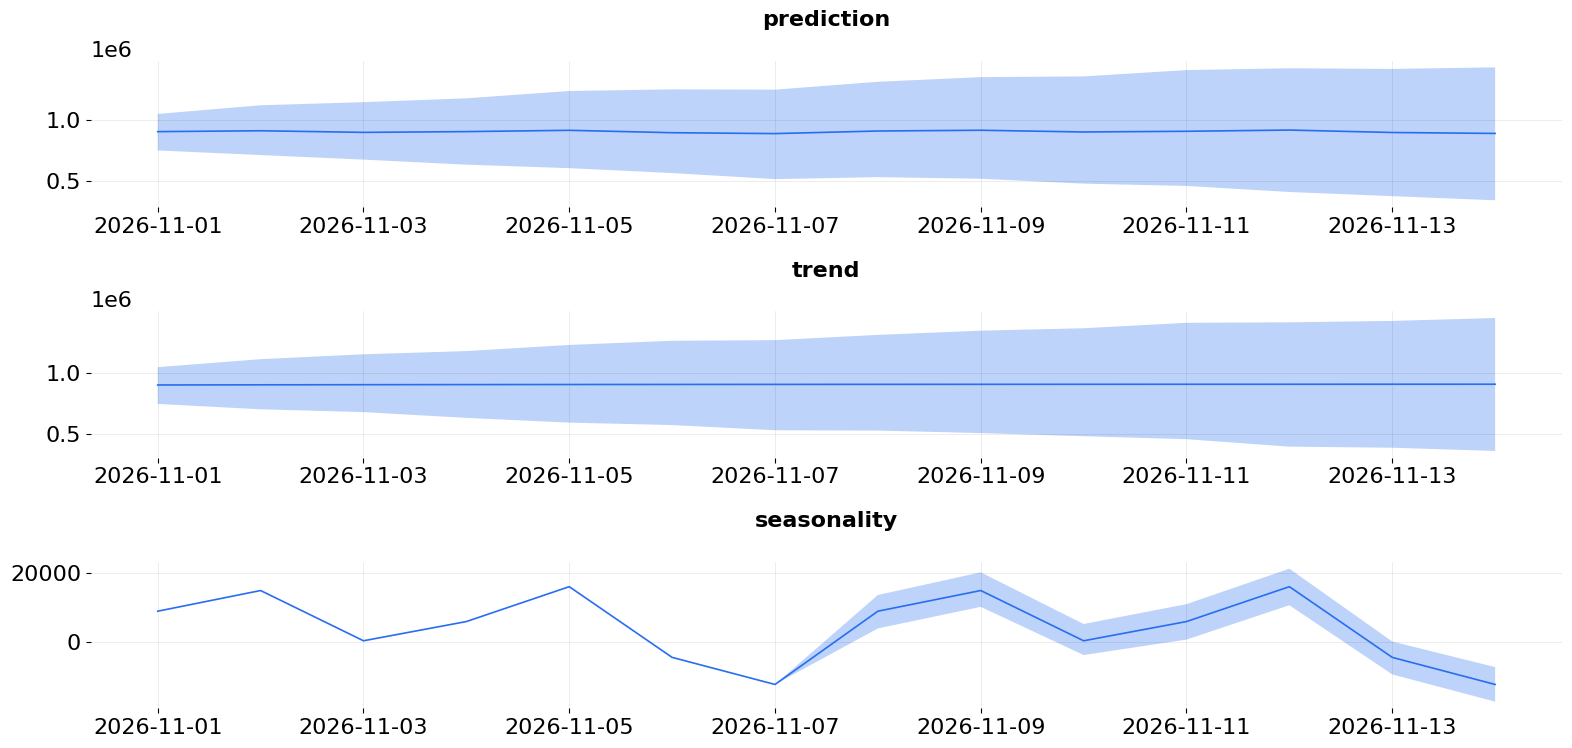

array([<Axes: title={'center': 'prediction'}>,
       <Axes: title={'center': 'trend'}>,
       <Axes: title={'center': 'seasonality'}>], dtype=object)

In [119]:
predicted_df_dtl_14 = dlt_14.predict(df=future_df_dtl_14, decompose=True)

plot_predicted_components(
    predicted_df_dtl_14,
    'date',
    plot_components=['prediction', 'trend', 'seasonality']
)

In [102]:
ets_14 = ETS(response_col="total_actions", #название колонки с метрикой
          date_col="date", #название колонки с датами-временем
          seasonality=7, #длина периода сезонности 
          estimator="stan-map", #алгоритм оценки
          n_bootstrap_draws=1000,
          num_warmup=2000, #время "разогрева"
          num_sample=1000) #количество сэмплов бутстрапа для доверительного интервала

In [103]:
# обучаем модель
ets_14.fit(train_14)

In [104]:
# датафрейм, для которого будем делать прогноз
future_df_ets_14 = ets_14.make_future_df(periods=horizon_14)

In [105]:
# прогнозирование
predicted_df_ets_14 = ets_14.predict(df=future_df_ets_14)

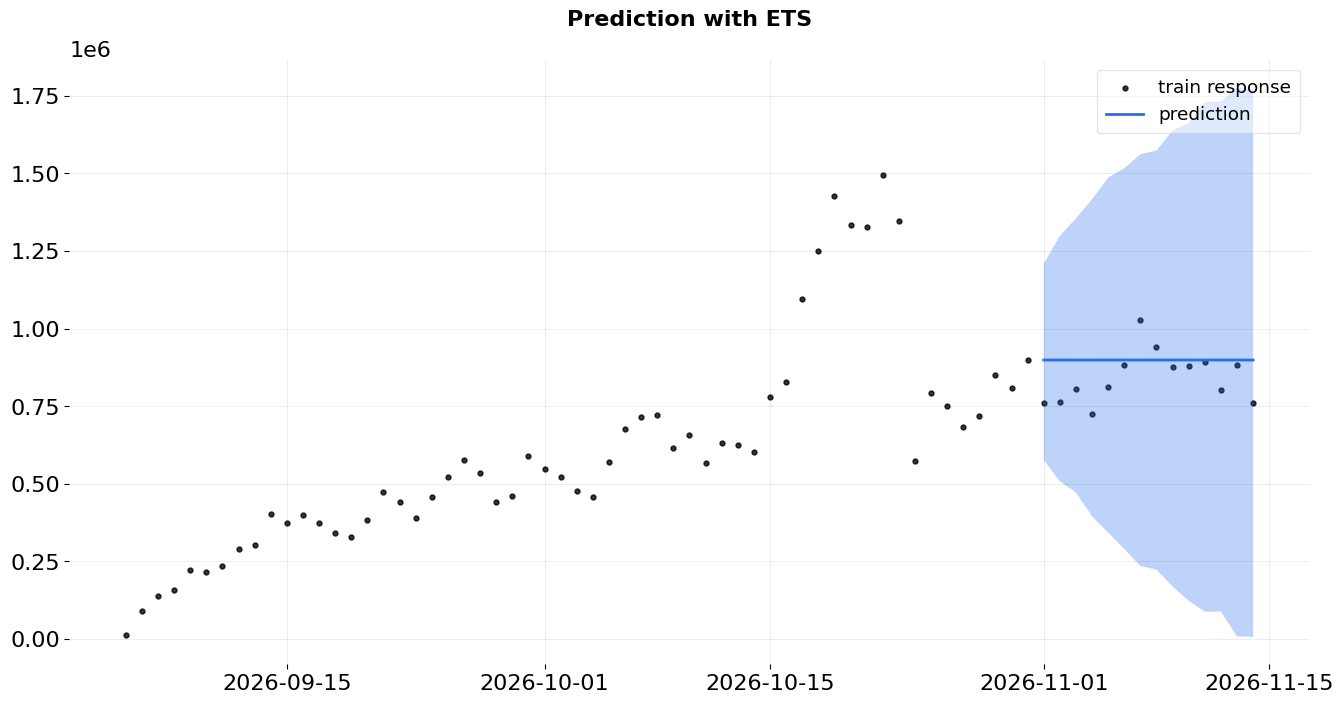

<Axes: title={'center': 'Prediction with ETS'}>

In [106]:
# визуализация прогноза
plot_predicted_data(daily_activity, #изначальные данные
                    predicted_df_ets_14, #датафрейм с предсказаниями
                    'date', #колонка со временем
                    'total_actions', #колонка со значениями временного ряда
                    title='Prediction with ETS') #заголовок рисунка

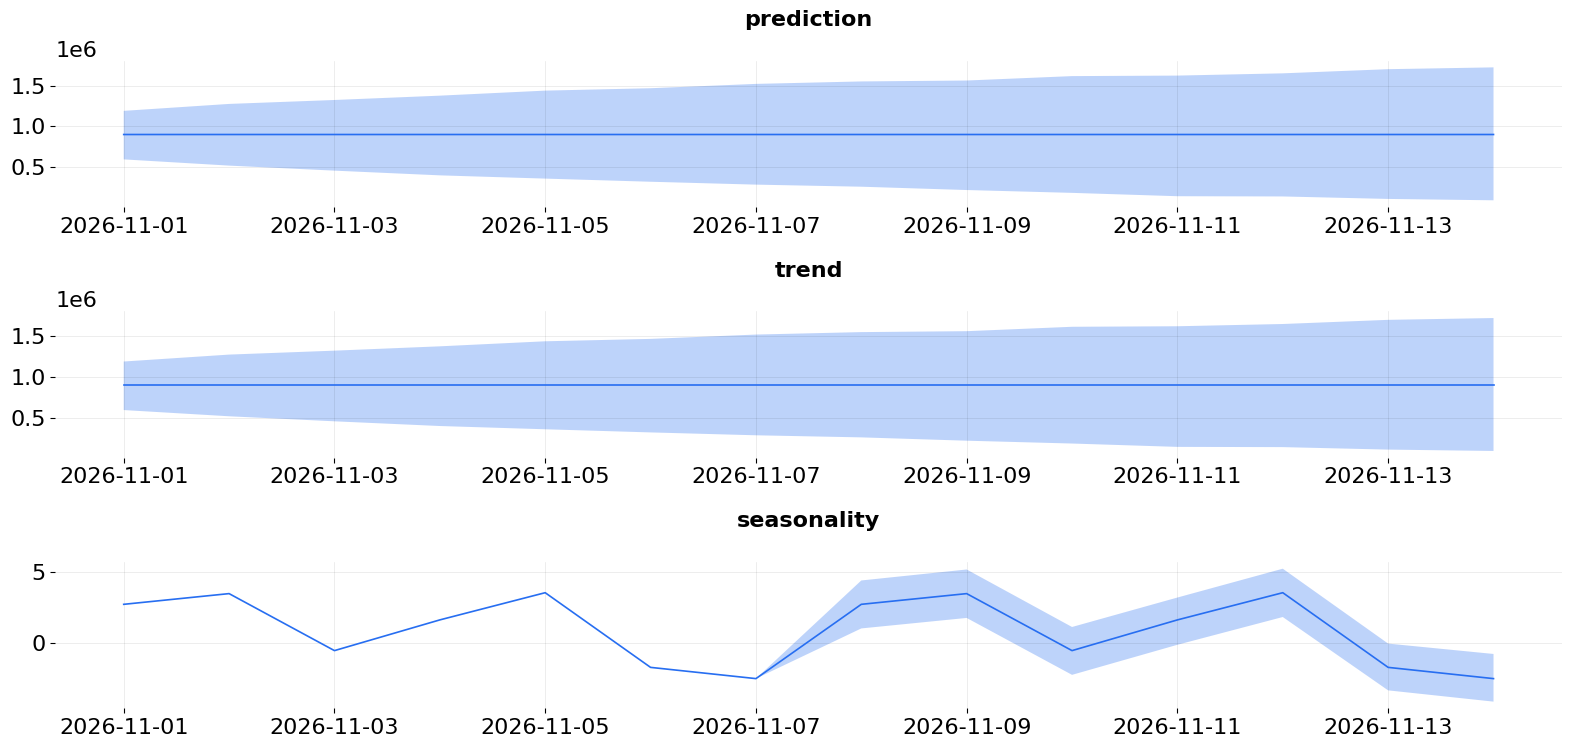

array([<Axes: title={'center': 'prediction'}>,
       <Axes: title={'center': 'trend'}>,
       <Axes: title={'center': 'seasonality'}>], dtype=object)

In [118]:
predicted_df_ets_14 = ets_14.predict(df=future_df_ets_14, decompose=True)

plot_predicted_components(
    predicted_df_ets_14,
    'date',
    plot_components=['prediction', 'trend', 'seasonality']
)

### Сравнение моделей

In [111]:
def run_backtest_14(model, data, horizon=14):
    bt = BackTester(
        model,
        data,
        min_train_len=35,
        incremental_len=7,
        forecast_len=horizon,
        window_type='expanding'
    )

    bt.fit_predict()

    return bt

In [120]:
bt_ets_14 = run_backtest_14(ets_14, daily_activity)
bt_dlt_14 = run_backtest_14(dlt_14, daily_activity)

results = []

for name, bt in [
    ('ETS', bt_ets_14),
    ('DLT', bt_dlt_14)
]:
    score = bt.score()

    score['model'] = name

    results.append(score)

comparison_14 = pd.concat(results, ignore_index=True)

comparison_14.pivot(
    index='model',
    columns='metric_name',
    values='metric_values'
).round(3)

metric_name,mae,mape,mse,rmsse,smape,wmape
model,,,,,,
DLT,339716.037,0.384,1.713467e+11,2.640,0.332,0.372
ETS,336558.873,0.359,1.907647e+11,2.785,0.337,0.368


При увеличении горизонта прогнозирования с 7 до 14 дней качество обеих моделей снизилось: значения MAE, MAPE и SMAPE возросли. На горизонте 14 дней ETS показала немного лучшие результаты по MAE, MAPE и WMAPE, тогда как DLT оказалась лучше по MSE, RMSSE и SMAPE. Существенного преимущества одной модели над другой не выявлено, поэтому обе модели сохраняются для дальнейшего анализа.

## DLT и ETS на горизонте 30 дней

In [145]:
# определяем тренировочные и тестовые данные (на 30 дней)
horizon_30 = 30

train_30 = daily_activity.iloc[:-horizon_30]
test_30 = daily_activity.iloc[-horizon_30:]

print('Train:', len(train_30))
print('Test:', len(test_30))
print('Train dates:', train_30['date'].min(), '-', train_30['date'].max())
print('Test dates:', test_30['date'].min(), '-', test_30['date'].max())

train_30.head()

Train: 41
Test: 30
Train dates: 2026-09-05 00:00:00 - 2026-10-15 00:00:00
Test dates: 2026-10-16 00:00:00 - 2026-11-14 00:00:00


,date,total_actions,dau,total_actions_feed,dau_feed,total_actions_message,dau_message
0,2026-09-05,12389,1045,9163,878,3226,234
1,2026-09-06,88481,2494,75586,2238,12895,623
2,2026-09-07,139381,3396,126484,3105,12897,522
3,2026-09-08,155693,4011,142796,3721,12897,498
4,2026-09-09,221856,4997,208958,4617,12898,691


In [128]:
dlt_30 = DLT(response_col="total_actions", #название колонки с метрикой
          date_col="date", #название колонки с датами-временем
          seasonality=7, #длина периода сезонности 
          estimator="stan-map", #алгоритм оценки
          n_bootstrap_draws=1000,
          num_warmup=2000, #время "разогрева"
          num_sample=1000) #количество сэмплов бутстрапа для доверительного интервала

In [129]:
# обучаем модель
dlt_30.fit(train_30)

In [130]:
# датафрейм, для которого будем делать прогноз
future_df_dtl_30 = dlt_30.make_future_df(periods=horizon_30)

In [131]:
# прогнозирование
predicted_df_dtl_30 = dlt_30.predict(df=future_df_dtl_30)

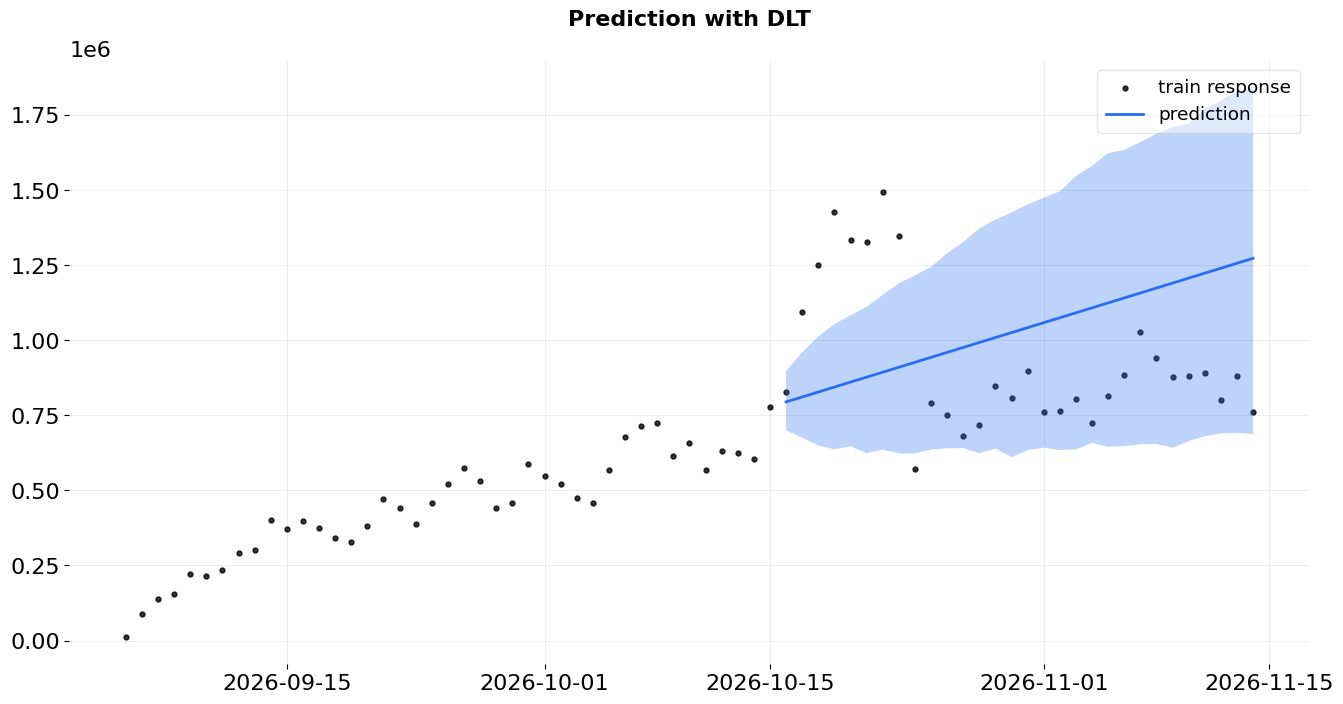

<Axes: title={'center': 'Prediction with DLT'}>

In [132]:
# визуализация прогноза
plot_predicted_data(daily_activity, #изначальные данные
                    predicted_df_dtl_30, #датафрейм с предсказаниями
                    'date', #колонка со временем
                    'total_actions', #колонка со значениями временного ряда
                    title='Prediction with DLT') #заголовок рисунка

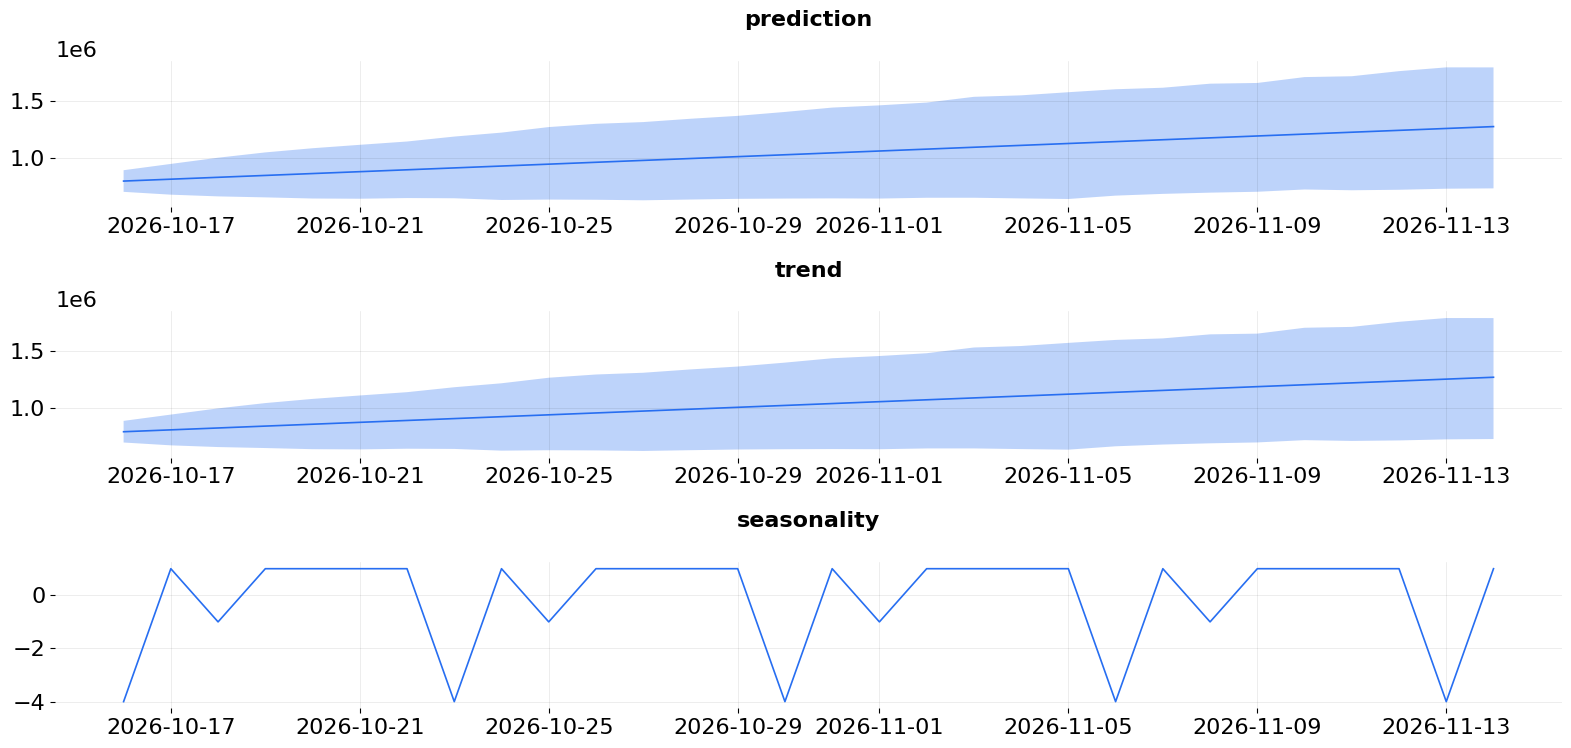

array([<Axes: title={'center': 'prediction'}>,
       <Axes: title={'center': 'trend'}>,
       <Axes: title={'center': 'seasonality'}>], dtype=object)

In [133]:
predicted_df_dtl_30 = dlt_30.predict(df=future_df_dtl_30, decompose=True)

plot_predicted_components(
    predicted_df_dtl_30,
    'date',
    plot_components=['prediction', 'trend', 'seasonality']
)

In [134]:
ets_30 = ETS(response_col="total_actions", #название колонки с метрикой
          date_col="date", #название колонки с датами-временем
          seasonality=7, #длина периода сезонности 
          estimator="stan-map", #алгоритм оценки
          n_bootstrap_draws=1000,
          num_warmup=2000, #время "разогрева"
          num_sample=1000) #количество сэмплов бутстрапа для доверительного интервала

In [135]:
# обучаем модель
ets_30.fit(train_30)

In [136]:
# датафрейм, для которого будем делать прогноз
future_df_ets_30 = ets_30.make_future_df(periods=horizon_30)

In [137]:
# прогнозирование
predicted_df_ets_30 = ets_30.predict(df=future_df_ets_30)

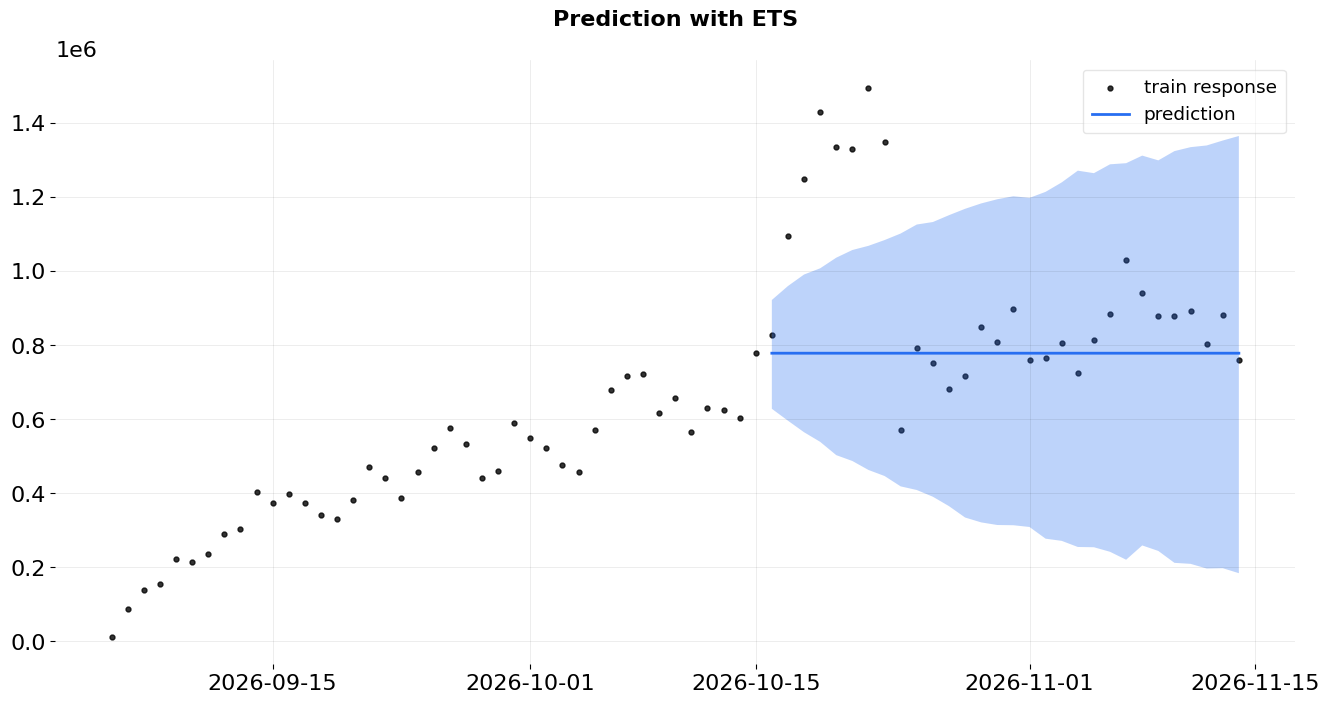

<Axes: title={'center': 'Prediction with ETS'}>

In [138]:
# визуализация прогноза
plot_predicted_data(daily_activity, #изначальные данные
                    predicted_df_ets_30, #датафрейм с предсказаниями
                    'date', #колонка со временем
                    'total_actions', #колонка со значениями временного ряда
                    title='Prediction with ETS') #заголовок рисунка

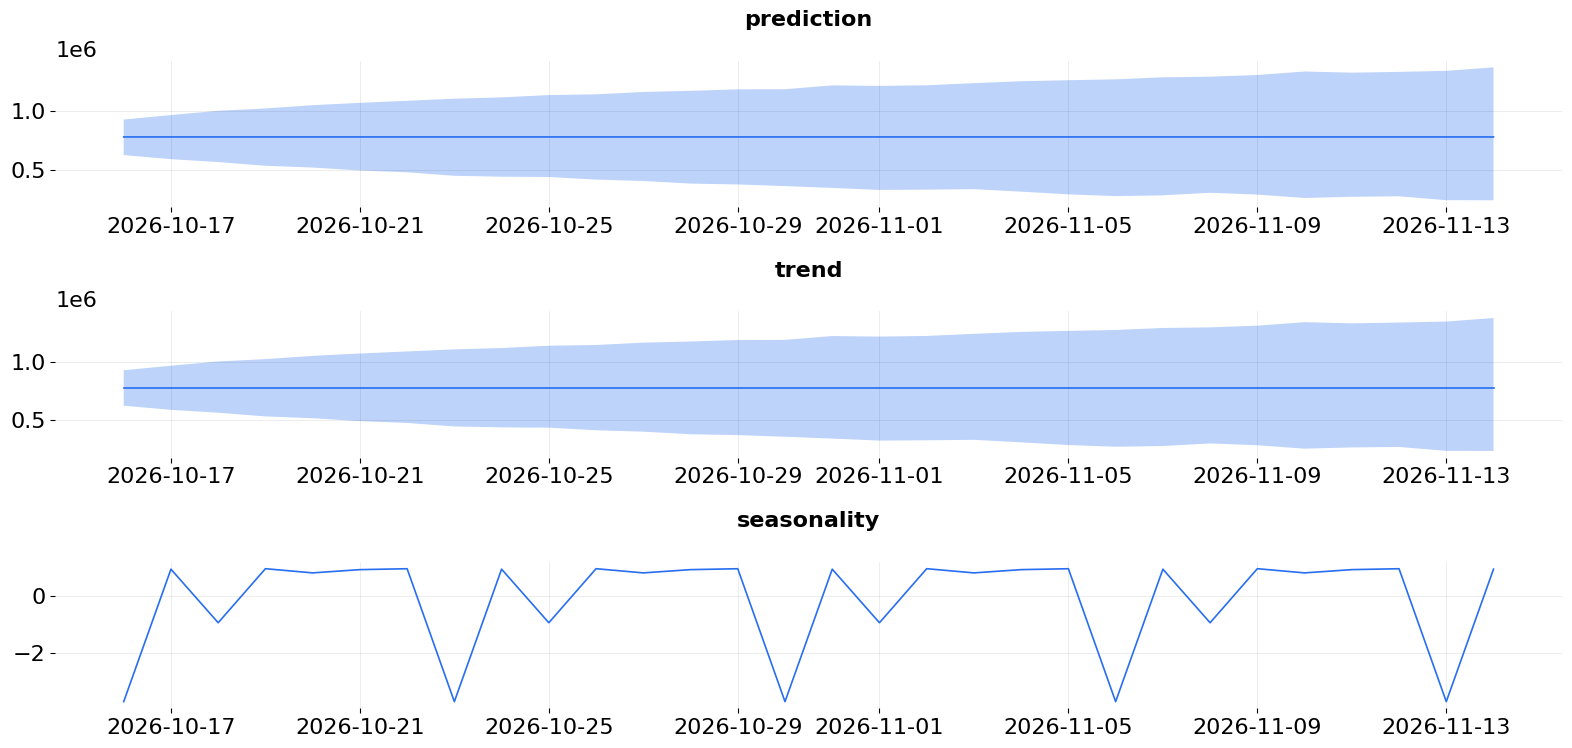

array([<Axes: title={'center': 'prediction'}>,
       <Axes: title={'center': 'trend'}>,
       <Axes: title={'center': 'seasonality'}>], dtype=object)

In [139]:
predicted_df_ets_30 = ets_30.predict(df=future_df_ets_30, decompose=True)

plot_predicted_components(
    predicted_df_ets_30,
    'date',
    plot_components=['prediction', 'trend', 'seasonality']
)

In [142]:
def run_backtest_30(model, data, horizon=30):
    bt = BackTester(
        model,
        data,
        min_train_len=35,
        incremental_len=7,
        forecast_len=horizon,
        window_type='expanding'
    )

    bt.fit_predict()

    return bt

In [146]:
bt_ets_30 = run_backtest_30(ets_30, daily_activity)
bt_dlt_30 = run_backtest_30(dlt_30, daily_activity)

results = []

for name, bt in [
    ('ETS', bt_ets_30),
    ('DLT', bt_dlt_30)
]:
    score = bt.score()

    score['model'] = name

    results.append(score)

comparison_30 = pd.concat(results, ignore_index=True)

comparison_30.pivot(
    index='model',
    columns='metric_name',
    values='metric_values'
).round(3)

metric_name,mae,mape,mse,rmsse,smape,wmape
model,,,,,,
DLT,229075.213,0.234,8.877856e+10,1.617,0.243,0.257
ETS,282870.326,0.266,1.469941e+11,2.081,0.332,0.317


На данный момент DLT выглядит наиболее перспективной моделью. Она лидирует на 7- и 30-дневном горизонтах по большинству метрик, а на 14 днях показывает сопоставимое с ETS качество. Добавление DAU в качестве регрессора не улучшило результат. 
Но преимущество DLT на 30 днях пока нужно трактовать осторожно, так как мало данных для обучения и есть особенность тестового периода (проведение флешмоба).

In [158]:
# Сравнение фактических значений и прогноза
comparison_dlt_30 = test_30[['date', 'total_actions']].merge(
    predicted_df_dtl_30[
        ['date', 'prediction', 'prediction_5', 'prediction_95']
    ],
    on='date',
    how='inner'
)

comparison_dlt_30['error'] = (
    comparison_dlt_30['total_actions'] -
    comparison_dlt_30['prediction']
)

comparison_dlt_30['abs_error'] = comparison_dlt_30['error'].abs()

comparison_dlt_30['ape'] = (
    comparison_dlt_30['abs_error'] /
    comparison_dlt_30['total_actions'] * 100
)

comparison_dlt_30

,date,total_actions,prediction,prediction_5,prediction_95,error,abs_error,ape
0,2026-10-16,827265,7.945433e+05,699980.082043,8.897721e+05,32721.722327,32721.722327,3.955410
1,2026-10-17,1095541,8.110374e+05,675129.351480,9.450613e+05,284503.579470,284503.579470,25.969232
2,2026-10-18,1249321,8.275246e+05,660085.116641,9.995594e+05,421796.436613,421796.436613,33.762054
3,2026-10-19,1427992,8.440157e+05,651435.443541,1.046116e+06,583976.293756,583976.293756,40.894928
4,2026-10-20,1333477,8.605048e+05,641412.453035,1.082742e+06,472972.150899,472972.150899,35.469090
5,2026-10-21,1328223,8.769940e+05,639508.921879,1.112726e+06,451229.008041,451229.008041,33.972383
6,2026-10-22,1494743,8.934831e+05,645425.564561,1.141777e+06,601259.865184,601259.865184,40.224966
7,2026-10-23,1347199,9.099673e+05,643641.376083,1.185149e+06,437231.722327,437231.722327,32.454873
8,2026-10-24,572002,9.264614e+05,628560.331057,1.219862e+06,-354459.420530,354459.420530,61.968213
9,2026-10-25,791740,9.429486e+05,632134.059939,1.268506e+06,-151208.563387,151208.563387,19.098260


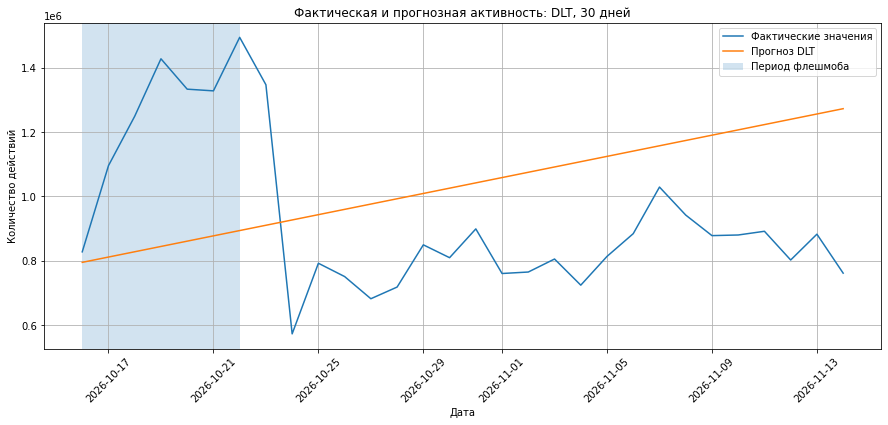

In [159]:
plt.figure(figsize=(15, 6))

plt.plot(
    comparison_dlt_30['date'],
    comparison_dlt_30['total_actions'],
    label='Фактические значения'
)

plt.plot(
    comparison_dlt_30['date'],
    comparison_dlt_30['prediction'],
    label='Прогноз DLT'
)

plt.axvspan(
    pd.Timestamp('2026-10-16'),
    pd.Timestamp('2026-10-22'),
    alpha=0.2,
    label='Период флешмоба'
)

plt.title('Фактическая и прогнозная активность: DLT, 30 дней')
plt.xlabel('Дата')
plt.ylabel('Количество действий')
plt.legend()
plt.xticks(rotation=45)
plt.grid()
plt.show()

In [164]:
# проверка ошибок по периодам
comparison_dlt_30['period'] = np.select(
    [
        comparison_dlt_30['date'].between('2026-10-16', '2026-10-22'),
        comparison_dlt_30['date'].between('2026-10-23', '2026-11-05')
    ],
    ['Флешмоб', 'После флешмоба'],
    default='Остальной период'
)

period_metrics = comparison_dlt_30.groupby('period').agg(
    MAE=('abs_error', 'mean'),
    MAPE=('ape', 'mean'),
    actual_mean=('total_actions', 'mean'),
    prediction_mean=('prediction', 'mean')
).round(2)

period_metrics

,MAE,MAPE,actual_mean,prediction_mean
period,,,,
Остальной период,323656.07,37.84,883119.44,1206775.52
После флешмоба,273702.81,35.09,805909.57,1017150.71
Флешмоб,406922.72,30.61,1250937.43,844014.71


## Итоговый прогноз на ближайшие 30 дней 

In [165]:
# Обучаем выбранную модель на всей доступной истории
dlt_final = DLT(
    response_col='total_actions',
    date_col='date',
    seasonality=7,
    estimator='stan-map',
    n_bootstrap_draws=1000,
    num_warmup=2000,
    num_sample=1000
)

In [166]:
dlt_final.fit(daily_activity)

In [167]:
# Формируем даты для прогноза
future_df_final = dlt_final.make_future_df(periods=30)

In [168]:
# Строим прогноз
predicted_df_final = dlt_final.predict(
    df=future_df_final
)

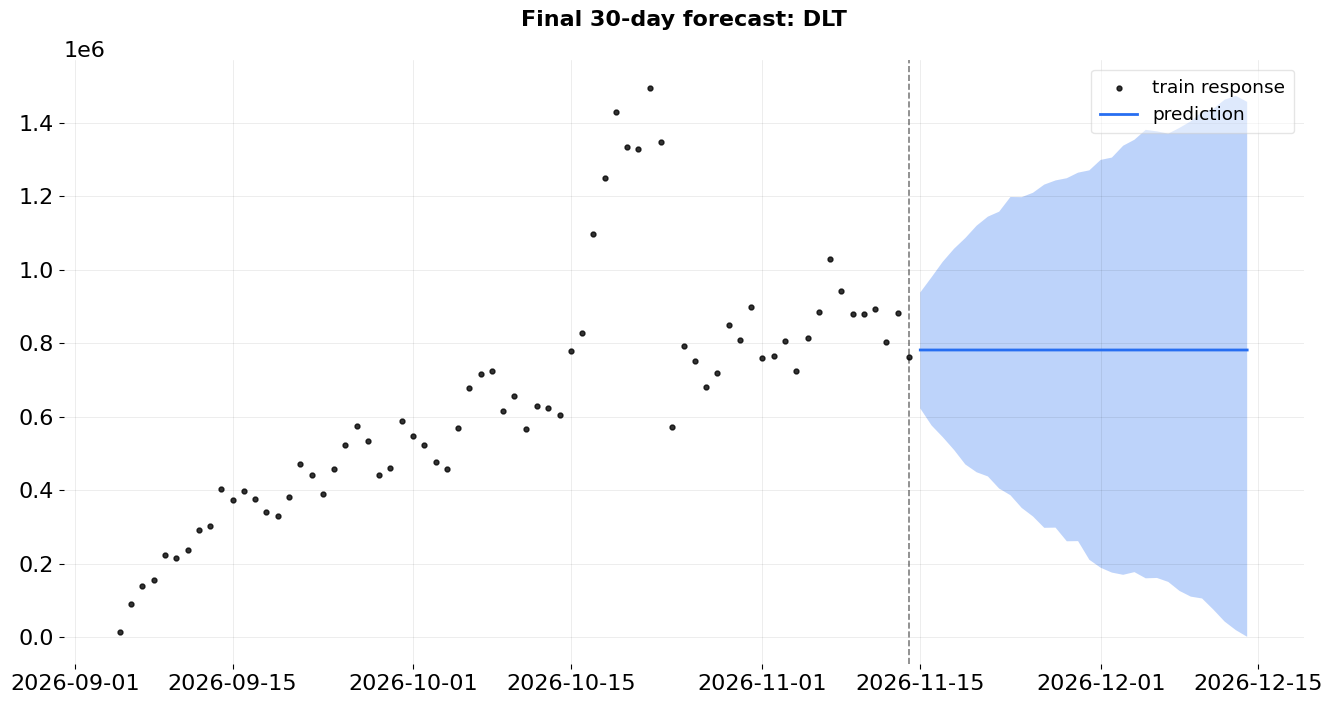

<Axes: title={'center': 'Final 30-day forecast: DLT'}>

In [169]:
# Визуализируем результат
plot_predicted_data(
    daily_activity,
    predicted_df_final,
    'date',
    'total_actions',
    title='Final 30-day forecast: DLT'
)

## Общий вывод по прогнозированию пользовательской активности

В ходе исследования были построены и сравнены четыре модели прогнозирования Orbit: ETS, LGT, KTR и DLT. В качестве целевой метрики использовалось общее количество действий пользователей в ленте и мессенджере ('total_actions'). Дополнительно была проверена возможность использования DAU в качестве регрессора.

**По результатам сравнения в качестве основной модели выбрана DLT.** На горизонте 7 дней она показала лучшие результаты по MAE, SMAPE и WMAPE. На горизонтах 7 и 14 дней результаты DLT и ETS были близкими, при этом явного преимущества одной модели по всем метрикам не наблюдалось. На горизонте 30 дней DLT показала лучшие результаты по всем рассмотренным метрикам по сравнению с ETS. KTR продемонстрировала существенно более высокую ошибку.

Добавление DAU в качестве регрессора не улучшило качество прогноза DLT в проведённом эксперименте. При этом использование регрессоров предполагает наличие их значений на весь прогнозируемый период. Если будущие значения регрессора неизвестны, их необходимо предварительно спрогнозировать отдельной моделью либо задать сценарные значения. В таком случае итоговый прогноз целевой метрики будет зависеть не только от качества основной модели, но и от точности прогноза регрессора. Также не использовались данные о флешмобе в качестве регрессора, поскольку информация о подобных событиях в будущем отсутствует.

### Достаточность данных для бэктестинга

В распоряжении имеется 71 дневное наблюдение. При минимальном размере обучающей выборки в 35 дней и шаге между тестовыми окнами в 7 дней количество возможных проверок сокращается с увеличением горизонта прогнозирования.

На горизонтах 7 и 14 дней можно провести несколько последовательных проверок, что позволяет получить более содержательную оценку качества моделей. Для горизонта 30 дней доступно фактически только одно тестовое окно.

Таким образом, имеющихся данных недостаточно для надёжной оценки качества 30-дневного прогноза с помощью многократного бэктестинга. Результаты на этом горизонте следует рассматривать как предварительные. Для более надёжной проверки потребуется накопить дополнительную историю наблюдений.

В рамках текущего исследования наиболее обоснованно использовать результаты бэктестинга на горизонтах 7 и 14 дней, а 30-дневный прогноз рассматривать как дополнительный эксперимент, соответствующий целевому горизонту задачи.

### Анализ прогноза на тестовом периоде

Дополнительно было проверено качество 30-дневного прогноза DLT на тестовом периоде с 16 октября по 14 ноября. Анализ показал, что модель не смогла предсказать резкий рост активности во время флешмоба 16–22 октября: фактическое количество действий значительно превысило прогноз. После завершения события модель продолжила прогнозировать рост активности, хотя фактические значения снизились. Это привело к систематическому завышению прогноза в последующий период.

### Итог

DLT является наиболее перспективной из рассмотренных моделей для дальнейшего прогнозирования пользовательской активности. При этом её преимущество на 30-дневном горизонте пока нельзя считать окончательно подтверждённым из-за ограниченного количества тестовых окон.

Полученные результаты показывают, что модель способна описывать общую динамику активности, но плохо учитывает резкие изменения, вызванные непредсказуемыми внешними событиями. Кроме того, общее количество действий за день является лишь приближённой оценкой нагрузки на серверы и не отражает внутридневные пики активности.

Для более надёжного прогнозирования необходимо накопить дополнительную историю наблюдений.